---
title: "Лекція 4. Виявлення структури в даних та валідація отриманих закономірностей"
description: "Машинне навчання та методи вилучення знань | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mlkdd-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

## Мета лекції

Сформувати здатність досліджувати *приховану структуру даних* за допомогою методів навчання без учителя та оцінювати, чи є виявлені закономірності стійкими, змістовними і придатними для обґрунтування наукового твердження.

## Очікувані результати навчання

Після лекції аспірант зможе: розрізняти структуру даних і артефакт алгоритму; обґрунтовувати вибір метрики відстані, масштабування й кількості кластерів; застосовувати PCA та кластеризацію як інструменти дослідження; оцінювати внутрішню, зовнішню та стабільнісну валідацію; формулювати межі інтерпретації латентних представлень.

## План лекції

1. Структура як гіпотеза, а не готовий факт.
2. Геометрія простору ознак і передобробка.
3. PCA: латентні напрями варіації.
4. Кластеризація: модельне припущення про групи.
5. Критерії якості та вибір кількості кластерів.
6. Стабільність, нульові моделі та зовнішня перевірка.
7. Наукова інтерпретація і межі висновку.
8. Перехід до ЛР4.

Ключові джерела: [@hastie2009elements; @bishop2006prml; @breiman2001two].


## 1. Що означає «виявити структуру»?

*Структура даних (data structure)* -- це відносно стійкі відношення між спостереженнями чи ознаками: групи, неперервні градієнти, підпростори, фактори, топологічні зв'язки. Алгоритм завжди повертає певне представлення, але саме по собі це не доводить існування об'єктивних категорій у досліджуваній популяції.

Потрібно розрізняти три рівні:

- *алгоритмічний результат*: конкретне розбиття або проєкція;
- *емпірична закономірність*: структура, що зберігається за обґрунтованих змін протоколу;
- *наукове знання*: закономірність, для якої визначено інтерпретацію, межі застосовності й альтернативні пояснення.

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Дослідницьке<br/>питання") --> B("Ознаки та<br/>геометрія")
 B --> C("Метод пошуку<br/>структури")
 C --> D("Внутрішня<br/>валідація")
 D --> E("Стабільність і<br/>нульова модель")
 E --> F("Предметна<br/>інтерпретація")
 F --> G("Обмежене<br/>твердження")
```

## 2. Геометрія визначає результат

Для векторів $x_i,x_j\in\mathbb{R}^p$ евклідова відстань:

$$
d_2(x_i,x_j)=\sqrt{\sum_{k=1}^{p}(x_{ik}-x_{jk})^2}.
$$

Якщо одна ознака вимірюється в тисячах, а інша -- у частках одиниці, перша може домінувати. Стандартизація

$$
z_{ik}=\frac{x_{ik}-\bar{x}_k}{s_k}
$$
змінює геометрію і, відповідно, структуру, яку «бачить» алгоритм. Це не нейтральна технічна операція, а *дослідницьке рішення*.

Для текстових embedding-просторів може бути змістовнішою косинусна подібність; для часових рядів -- спеціальні часові відстані; для графів -- структурні метрики. Вибір має випливати з RQ.

### Простий ручний приклад

Нехай $A=(0,0)$, $B=(1,10)$, $C=(3,0)$. Тоді $d(A,B)=\sqrt{101}\approx10.05$, а $d(A,C)=3$. Якщо друга координата змінює масштаб у 10 разів, порядок близькості може змінитися. Отже, кластеризація без опису метрики й масштабування не є повністю відтворюваною.


## 3. Метод головних компонент (PCA)

PCA шукає ортогональні напрями максимальної дисперсії. Для центрованої матриці $X_c\in\mathbb{R}^{n\times p}$:

$$
S=\frac{1}{n-1}X_c^\top X_c,\qquad Sv_j=\lambda_jv_j.
$$

Проєкція на перші $q$ компонент:

$$
Z_q=X_cV_q.
$$

Частка поясненої дисперсії:

$$
\mathrm{EVR}_q=\frac{\sum_{j=1}^{q}\lambda_j}{\sum_{j=1}^{p}\lambda_j}.
$$

*Важливо:* висока EVR не означає, що компоненти є причинами явища, а низьковимірна візуалізація може приховувати відмінності, суттєві у вихідному просторі [@hastie2009elements].

### Ручний мініприклад

Для центрованих точок $(-2,-2),(0,0),(2,2)$ маємо

$$
S=\begin{pmatrix}4&4\\4&4\end{pmatrix},
\quad\lambda_1=8,\quad\lambda_2=0,
\quad v_1=\frac{1}{\sqrt2}(1,1)^\top.
$$

Усі спостереження лежать на одній прямій, тому перша компонента пояснює 100% дисперсії. Але з цього не випливає, що в даних існують *два чи три кластери*.

## 4. Навчальний експеримент: PCA та k-means

Згенеруємо синтетичні дані з трьома групами та додатковими шумовими ознаками. Експеримент демонструє, як вибір простору ознак впливає на кластеризацію; він не доводить існування таких груп у реальній предметній області.


Форма матриці: (360, 7)
Частка дисперсії перших двох ПК: [0.206 0.16 ]


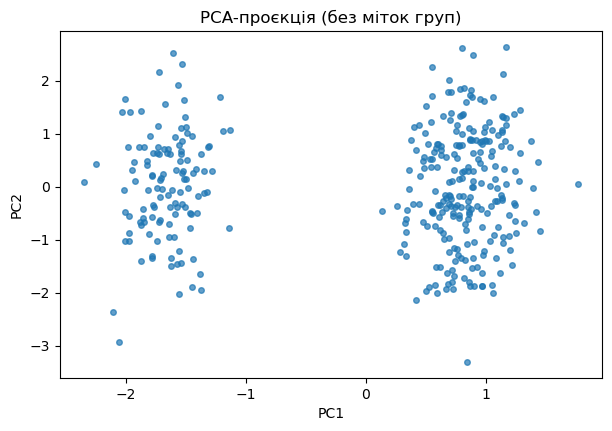

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 42
rng = np.random.default_rng(SEED)
X_signal, y_true = make_blobs(n_samples=360, centers=3,
                              cluster_std=[0.65, 0.8, 0.7], random_state=SEED)
X = np.column_stack([X_signal, rng.normal(0, 1, size=(len(X_signal), 5))])
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(X_scaled)
print("Форма матриці:", X.shape)
print("Частка дисперсії перших двох ПК:", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Z[:, 0], Z[:, 1], s=16, alpha=0.7)
ax.set(xlabel="PC1", ylabel="PC2", title="PCA-проєкція (без міток груп)")
plt.show()


## 5. Кластеризація як оптимізаційна задача

Метод *k-середніх (k-means)* шукає розбиття на $K$ груп і центроїди $\mu_k$, що мінімізують внутрішньокластерну суму квадратів:

$$
J=\sum_{k=1}^{K}\sum_{i\in C_k}\|x_i-\mu_k\|_2^2.
$$

Метод віддає перевагу приблизно компактним кластерам в обраній геометрії. Встановлене $K$ -- припущення дослідника, а не число, яке алгоритм «відкрив» незалежно від нього.

Альтернативи: ієрархічна кластеризація (ієрархія вкладених груп), DBSCAN (щільнісні області й шум), суміші гаусівських розподілів (імовірнісна модель латентних компонент). Вони відповідають різним уявленням про структуру [@bishop2006prml].

## 6. Внутрішні критерії якості

*Коефіцієнт силуету (silhouette coefficient)* для об'єкта $i$:

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}},
$$
де $a(i)$ -- середня відстань до об'єктів власного кластера, $b(i)$ -- найменша середня відстань до іншого кластера. Значення лежить у $[-1,1]$.

Високий silhouette означає добру геометричну відокремленість *за обраною метрикою*, але не доводить змістовність груп. Порівняння різних $K$ за одним критерієм може бути нестійким; оцінка має доповнюватися перевіркою припущень і стабільності.

### Експеримент: вибір K


C:\Users\Valeriy\miniconda3\envs\ml-mke\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,K,silhouette,inertia
0,2,0.217,2014.629
1,3,0.167,1813.421
2,4,0.157,1683.379
3,5,0.139,1579.447
4,6,0.153,1472.369
5,7,0.151,1403.966


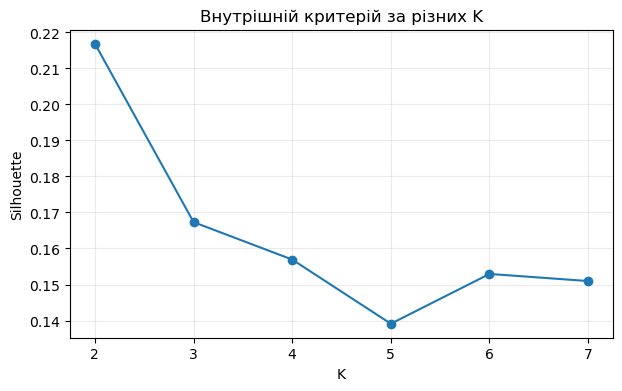

In [2]:
rows = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = km.fit_predict(X_scaled)
    rows.append({"K": k, "silhouette": silhouette_score(X_scaled, labels),
                 "inertia": km.inertia_})
results = pd.DataFrame(rows)
display(results.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results["K"], results["silhouette"], marker="o")
ax.set(xlabel="K", ylabel="Silhouette", title="Внутрішній критерій за різних K")
ax.grid(alpha=0.25)
plt.show()


## 7. Внутрішня, зовнішня та стабільнісна валідація

- *Внутрішня*: silhouette, Davies–Bouldin, Calinski–Harabasz, реконструкційна помилка. Вимірюють властивості структури у вибраному представленні.
- *Зовнішня*: порівняння з незалежними предметними мітками, якщо вони існують. Наприклад, adjusted Rand index (ARI) коригує узгодженість двох розбиттів на випадковий збіг.
- *Стабільнісна*: чи зберігається структура за допустимих змін вибірки, ініціалізації, метрики та представлення.

Відсутність зовнішніх міток -- нормальна ситуація для KDD; тоді слід особливо обережно формулювати наукове твердження. Використання тих самих міток і для підбору процедури, і для «незалежної» перевірки створює методологічну залежність.

### Зовнішня перевірка у синтетичному прикладі

У нашому контрольованому генераторі мітки $y_{true}$ відомі, але алгоритм їх не використовує. Це дає змогу порівняти внутрішній і зовнішній критерії.


Silhouette: 0.167
ARI (лише для синтетичної перевірки): 0.538


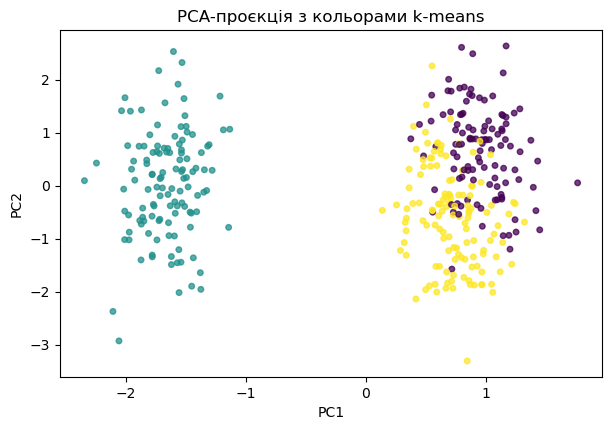

In [3]:
km3 = KMeans(n_clusters=3, n_init=20, random_state=SEED)
lab3 = km3.fit_predict(X_scaled)
print("Silhouette:", round(silhouette_score(X_scaled, lab3), 3))
print("ARI (лише для синтетичної перевірки):", round(adjusted_rand_score(y_true, lab3), 3))
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(Z[:, 0], Z[:, 1], c=lab3, s=16, alpha=0.75)
ax.set(xlabel="PC1", ylabel="PC2", title="PCA-проєкція з кольорами k-means")
plt.show()


## 8. Стабільність за зміни вибірки

Незалежні підвибірки мають різні множини об'єктів; безпосередньо порівнювати їхні кластерні мітки некоректно. Один простий контроль -- навчати k-means на різних підвибірках і порівнювати *передбачені кластери для фіксованої референсної множини*. ARI інваріантний до перестановки номерів кластерів.

Це ілюстрація *algorithmic stability*, а не повноцінна статистична гарантія існування кластерів у популяції.


In [4]:
from sklearn.model_selection import ShuffleSplit
splitter = ShuffleSplit(n_splits=12, train_size=0.8, random_state=SEED)
reference = X_scaled[:100]
reference_labels = []
for train_idx, _ in splitter.split(X_scaled):
    km = KMeans(n_clusters=3, n_init=20, random_state=SEED)
    km.fit(X_scaled[train_idx])
    reference_labels.append(km.predict(reference))
ari_to_first = [adjusted_rand_score(reference_labels[0], z) for z in reference_labels[1:]]
print("ARI до першого розбиття на референсній множині:")
print(pd.Series(ari_to_first).describe().round(3))


ARI до першого розбиття на референсній множині:
count    11.000
mean      0.603
std       0.029
min       0.563
25%       0.569
50%       0.619
75%       0.619
max       0.640
dtype: float64


## 9. Нульова модель: чи є результат нетривіальним?

Навіть без природних кластерів k-means поверне $K$ груп. Тому корисно порівнювати критерій із *нульовою моделлю (null model)*, яка зберігає деякі властивості даних, але руйнує структуру, що нас цікавить.

Нижче переставляємо значення *кожної ознаки незалежно*, зберігаючи її одномірний емпіричний розподіл, але руйнуючи міжознакові залежності. Це лише один можливий нульовий механізм; його адекватність залежить від RQ.


Observed silhouette: 0.167
Null mean (SD): 0.119 ( 0.005 )


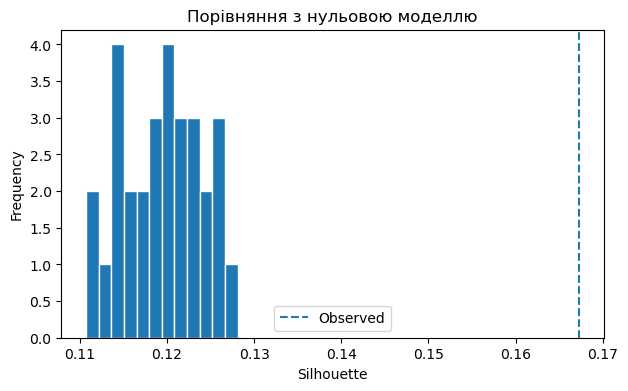

In [5]:
observed = silhouette_score(X_scaled, lab3)
null_scores = []
rng_null = np.random.default_rng(SEED + 10)
for b in range(30):
    X_null = np.column_stack([rng_null.permutation(X_scaled[:, j])
                              for j in range(X_scaled.shape[1])])
    null_lab = KMeans(n_clusters=3, n_init=10, random_state=SEED+b).fit_predict(X_null)
    null_scores.append(silhouette_score(X_null, null_lab))
print("Observed silhouette:", round(observed, 3))
print("Null mean (SD):", round(np.mean(null_scores), 3),
      "(", round(np.std(null_scores, ddof=1), 3), ")")
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(null_scores, bins=12, edgecolor="white")
ax.axvline(observed, linestyle="--", label="Observed")
ax.set(xlabel="Silhouette", ylabel="Frequency", title="Порівняння з нульовою моделлю")
ax.legend()
plt.show()


## 10. Коли візуалізація вводить в оману

PCA, t-SNE та UMAP -- методи побудови представлень із різними цілями. Відстані й площі на двовимірному графіку не завжди зберігають властивості вихідного простору. Зокрема, t-SNE/UMAP можуть створювати візуально виразні «острови» навіть там, де предметна інтерпретація кластерів не обґрунтована.

Не слід визначати число кластерів лише за виглядом 2D-проєкції. Якщо кластеризацію виконано в повному просторі, потрібно прямо зазначити, що рисунок є лише *візуалізацією*, а не незалежною перевіркою.

## 11. Типові загрози валідності структури

| Загроза | Механізм | Контроль |
|---|---|---|
| Масштаб ознак | Домінування змінних з великими одиницями | Порівняти обґрунтовані схеми масштабування |
| Метрика відстані | Зміна геометрії близькості | Обґрунтувати метрику предметно |
| Вибір $K$ | Підгонка під бажане розбиття | Задати протокол вибору і альтернативи |
| Шумові ознаки | Розмивання відстаней | Аудит ознак, контроль чутливості |
| Випадкова ініціалізація | Локальні оптимуми | Повторні ініціалізації |
| Зміна вибірки | Нестійкі групи | Ресемплінг із коректною одиницею |
| Зсув домену | Структура не переноситься | Зовнішня/часова перевірка |
| Постфактум-інтерпретація | Приписування групам неперевірених значень | Незалежні змінні та альтернативні пояснення |

## 12. Від закономірності до наукового твердження

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart TD
 A("Алгоритм виявив<br/>структуру") --> B{"Стійкість<br/>перевірена?"}
 B -->|Ні| C("Попередній<br/>результат")
 B -->|Так| D{"Нульові та<br/>альтернативні пояснення?"}
 D -->|Ні| E("Обмежене<br/>емпіричне спостереження")
 D -->|Так| F("Предметна перевірка<br/>та межі узагальнення")
 F --> G("Аргументоване<br/>наукове твердження")
```

*Приклад обережного формулювання:* «У межах вибірки та заданої метрики виявлено три відносно стійкі групи; їх предметний зміст потребує незалежної перевірки». Надмірне формулювання: «Доведено існування трьох природних типів об'єктів».

## 13. Зв'язок із дисертаційним дослідженням

Для своєї теми визначте: (1) яку приховану структуру шукаєте; (2) одиницю аналізу; (3) метрику/представлення; (4) нульову модель; (5) критерій стійкості; (6) незалежну предметну перевірку; (7) межі наукового твердження.

Цей перелік стане основою **ЛР4 «Виявлення та валідація прихованої структури і закономірностей у даних»**. Вона продовжить наскрізний артефакт попередніх лабораторних, але змістить акцент із прогнозної якості на обґрунтованість відкритої структури.

## Контрольні питання

1. Чим алгоритмічне розбиття відрізняється від емпіричної закономірності?  
2. Чому масштабування є дослідницьким рішенням?  
3. Що оптимізує PCA і чого не доводить висока EVR?  
4. Яке припущення про геометрію має k-means?  
5. Чому оптимальний silhouette не гарантує наукової значущості?  
6. Чим внутрішня валідація відрізняється від зовнішньої?  
7. Як ARI уникає проблеми перестановки міток кластерів?  
8. Як перевіряти стабільність розбиттів на різних підвибірках?  
9. Навіщо потрібна нульова модель?  
10. Чому двовимірна проєкція не є доказом існування кластерів?  
11. Які альтернативні пояснення виявленої структури слід перевірити?  
12. Як сформулювати обмежене наукове твердження за результатами кластеризації?  

## Висновки

Виявлення структури -- це початок дослідження, а не його завершення. Надійне ML/KDD-твердження вимагає обґрунтування представлення й метрики, внутрішньої перевірки, аналізу стабільності, зіставлення з нульовою моделлю та предметної інтерпретації. У наступній лекції розглянемо інтерпретацію моделей і поясненний штучний інтелект.

## Література та ресурси

Основні джерела: [@hastie2009elements; @bishop2006prml; @breiman2001two]. Для практичної реалізації: [scikit-learn: Clustering](https://scikit-learn.org/stable/modules/clustering.html), [PCA](https://scikit-learn.org/stable/modules/decomposition.html#pca), [Clustering metrics](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation).

::: {#refs}
:::
